# Representação vetorial de textos

[▶ Abrir este notebook no Google Colab](https://colab.research.google.com/github/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_05/03_representacao_vetorial_de_textos.ipynb)

Os notebooks anteriores compararam quantidades entre grupos. Para comparar
documentos, precisamos primeiro decidir como um texto se torna uma estrutura
calculável.

## 1. *Bag of Words*: o que preserva e o que perde

*Bag of Words* representa um documento pelas frequências dos termos. Preserva
parte do vocabulário e da repetição, mas descarta ordem, sintaxe, ironia,
negação, voz e grande parte do contexto.

`"trabalho não é progresso"` e `"progresso não é trabalho"` recebem as mesmas
contagens sob esta representação. Isso não é erro de programação: é uma perda
deliberada do modelo.

![Documentos preservados passam por normalização e tokens, formam um vocabulário e chegam a uma matriz de documentos por termos; uma nota registra a perda de ordem e sintaxe.](imagens/03_fluxo_matriz_documento_termo.svg)

In [1]:
# @title Preparação do ambiente — execute esta célula no Google Colab
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

URL_REPOSITORIO = 'https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais.git'
REPOSITORIO = Path(
    "/content/disciplina_computacao_aplicada_humanidades_digitais"
)
PASTA_UNIDADE = REPOSITORIO / 'unidade_05'

try:
    import google.colab  # type: ignore  # noqa: F401
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

if EM_COLAB:
    if not (REPOSITORIO / ".git").exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "--branch",
                "main",
                URL_REPOSITORIO,
                str(REPOSITORIO),
            ],
            check=True,
        )

    PACOTES_COLAB = []
    ausentes = [
        especificacao
        for modulo, especificacao in PACOTES_COLAB
        if importlib.util.find_spec(modulo) is None
    ]
    if ausentes:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", *ausentes],
            check=True,
        )

    os.chdir(PASTA_UNIDADE)
    print("Ambiente preparado em:", Path.cwd())
else:
    print("Ambiente local: nenhuma clonagem necessária.")

Ambiente local: nenhuma clonagem necessária.


In [2]:
import math
import re
import unicodedata
from collections import Counter
import pandas as pd
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd())) if str(Path.cwd()) not in sys.path else None
from IPython.display import display
from graficos import mapa_calor

dados = pd.read_csv("dados/documentos_comparacao.csv")
dados["texto"] = dados["texto_comparacao"]
stopwords = {"a", "e", "o", "de", "do", "da", "em", "nas", "também"}

def tokenizar(texto):
    normalizado = unicodedata.normalize("NFKD", texto.lower())
    sem_acentos = "".join(c for c in normalizado if not unicodedata.combining(c))
    return [t for t in re.findall(r"[a-z]+", sem_acentos) if t not in stopwords]

dados["tokens"] = dados["texto"].map(tokenizar)
dados[["id_documento", "tokens"]].head(3)

,id_documento,tokens
0,D001,"[escola, noturna, amplia, instrucao, publica, ..."
1,D002,"[trabalho, oficinas, reune, jornada, salario, ..."
2,D003,"[estrada, maquina, anunciam, progresso, tambem..."


A função explicita minúsculas, remoção de acentos, tokenização e *stopwords*.
Outra regra produziria outro vocabulário. Preservamos `texto` e o identificador
para poder retornar à fonte.

## 2. Matriz documento-termo

Se $c(t,d)$ é a contagem do termo $t$ no documento $d$, a matriz é:

$$
X_{d,t}=c(t,d).
$$

Linhas representam documentos; colunas, termos; células, frequências. Zero
significa ausência segundo as regras adotadas, não irrelevância histórica.

Dimensões: (12, 53)
Vocabulário: 53 termos


,escola,noturna,amplia,instrucao,publica,ensino,social,trabalho,oficinas,reune
id_documento,,,,,,,,,,
D001,1,1,1,1,1,1,1,1,1,1
D002,0,0,0,0,0,0,0,2,2,2
D003,0,0,0,0,0,0,0,0,0,0
D004,1,1,1,1,1,1,1,0,0,0
D005,2,2,2,2,2,2,2,2,2,2
D006,0,0,0,0,0,0,0,3,3,3


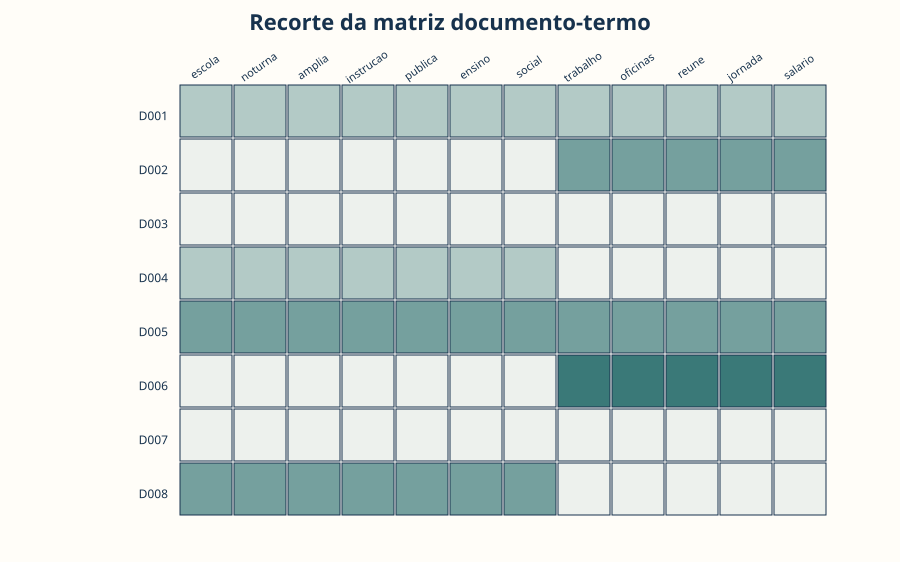

In [3]:
contagens = [Counter(tokens) for tokens in dados["tokens"]]
matriz_contagens = pd.DataFrame(contagens, index=dados["id_documento"]).fillna(0).astype(int)
matriz_contagens.index.name = "id_documento"
vocabulario = sorted(matriz_contagens.columns)
print("Dimensões:", matriz_contagens.shape)
print("Vocabulário:", len(vocabulario), "termos")
display(matriz_contagens.iloc[:6, :10])
mapa_calor(matriz_contagens.iloc[:8, :12], "Recorte da matriz documento-termo")

A matriz torna os documentos comparáveis, mas termos recorrentes em toda a
coleção podem dominar a contagem. TF-IDF acrescenta uma ponderação pela raridade
documental.

## 3. TF, DF, IDF e TF-IDF

Neste notebook, TF é a contagem bruta. A frequência de documento usa presença
positiva, e a convenção de IDF é suavizada:

$$
df(t)=\sum_{d=1}^{N}\mathbf{1}(X_{d,t}>0),\qquad
idf(t)=\log\left(\frac{N+1}{df(t)+1}\right)+1.
$$

Finalmente:

$$
tfidf(t,d)=X_{d,t}\times idf(t).
$$

A suavização, a base do logaritmo e a normalização variam entre implementações;
documentá-las é parte do método.

![TF mede frequência no documento, IDF mede raridade entre documentos e seu produto gera um peso; a figura alerta que peso não é importância histórica.](imagens/03_anatomia_tfidf.svg)

In [4]:
N = len(matriz_contagens)
frequencia_documento = matriz_contagens.gt(0).sum(axis=0)
idf = ((N + 1) / (frequencia_documento + 1)).map(math.log) + 1
matriz_tfidf = matriz_contagens.mul(idf, axis=1)
documento_exemplo = "D001"
comparacao_pesos = pd.DataFrame({
    "contagem": matriz_contagens.loc[documento_exemplo],
    "df": frequencia_documento,
    "idf": idf,
    "tfidf": matriz_tfidf.loc[documento_exemplo],
}).sort_values("tfidf", ascending=False)
comparacao_pesos.head(10).round(3)

,contagem,df,idf,tfidf
direcao,1,4,1.956,1.956
futuro,1,4,1.956,1.956
argumenta,1,4,1.956,1.956
sobre,1,4,1.956,1.956
prioridades,1,4,1.956,1.956
publica,1,6,1.619,1.619
instrucao,1,6,1.619,1.619
amplia,1,6,1.619,1.619
noturna,1,6,1.619,1.619
escola,1,6,1.619,1.619


Um peso alto identifica termo frequente no documento e relativamente raro na
coleção, sob esta regra. Não prova que o termo seja tema central, conceito
histórico ou escolha consciente do autor.

## 4. Comparar períodos e coleções

Agregar vetores por período permite localizar termos distintivos, mas o período
precisa ser definido antes da inspeção. Usaremos 1890–1895 e 1896–1901; os anos
posteriores não existem neste conjunto fictício.

In [5]:
periodo = pd.Series(
    pd.cut(dados["ano"], bins=[1889, 1895, 1901], labels=["1890–1895", "1896–1901"]).array,
    index=dados["id_documento"], name="periodo"
)
media_tfidf_periodo = matriz_tfidf.groupby(periodo, observed=True).mean()
contraste_periodos = (media_tfidf_periodo.loc["1890–1895"] - media_tfidf_periodo.loc["1896–1901"])
termos_periodo_inicial = contraste_periodos.nlargest(6).rename("favorece 1890–1895")
termos_periodo_final = contraste_periodos.nsmallest(6).rename("favorece 1896–1901")
tabela_contrastes = pd.concat([
    termos_periodo_inicial.rename("contraste").rename_axis("termo").reset_index().assign(sentido="maior em 1890–1895"),
    termos_periodo_final.rename("contraste").rename_axis("termo").reset_index().assign(sentido="maior em 1896–1901"),
], ignore_index=True)
display(tabela_contrastes[["termo", "contraste", "sentido"]].round(3))

,termo,contraste,sentido
0,trabalho,1.079,maior em 1890–1895
1,oficinas,1.079,maior em 1890–1895
2,reune,1.079,maior em 1890–1895
3,jornada,1.079,maior em 1890–1895
4,salario,1.079,maior em 1890–1895
5,estrada,1.079,maior em 1890–1895
6,escola,-1.079,maior em 1896–1901
7,noturna,-1.079,maior em 1896–1901
8,amplia,-1.079,maior em 1896–1901
9,instrucao,-1.079,maior em 1896–1901


## Aplicação ao projeto Goodreads

As células seguintes aplicam as operações do notebook à base do projeto.
Especificação principal: **E2** (rótulo original sem os 1.274 livros
duvidosos): 4.638 livros de autoria feminina (F) e 4.542 de autoria masculina
(M). A ordem das diferenças é sempre **F − M**: valor negativo indica menos
reconhecimento para livros de autoras.

In [6]:
# Localiza a pasta do projeto Goodreads (localmente ou no Colab, se a pasta for enviada para /content)
import sys
from pathlib import Path

CANDIDATOS = [Path("../projeto_goodreads"), Path("projeto_goodreads"), Path("/content/projeto_goodreads")]
PROJETO = next((c.resolve() for c in CANDIDATOS if (c / "preparar_base.py").exists()), None)
if PROJETO is None:
    raise FileNotFoundError(
        "Pasta projeto_goodreads não encontrada. Coloque-a ao lado das pastas unidade_0X "
        "ou, no Colab, envie-a para /content."
    )
if str(PROJETO) not in sys.path:
    sys.path.insert(0, str(PROJETO))
print("Projeto localizado:", (PROJETO / "preparar_base.py").exists())
from preparar_base import carregar_base_analitica
import numpy as np
import pandas as pd
from IPython.display import display

base = carregar_base_analitica()
ESPEC = {"E1 original": "genero_E1_original",
         "E2 sem duvidosos (principal)": "genero_E2_sem_duvidosos",
         "E3 reclassificada": "genero_E3_reclassificado"}
GRUPO = "genero_E2_sem_duvidosos"
e2 = base[base[GRUPO].notna()].copy()
e2["muito_avaliado"] = e2["n_avaliacoes"] >= 10_000
F = e2[GRUPO].eq("feminino")
M = e2[GRUPO].eq("masculino")
print("Especificação principal E2:", int(F.sum()), "livros de autoria feminina e", int(M.sum()), "de autoria masculina")

Projeto localizado: True
Especificação principal E2: 4638 livros de autoria feminina e 4542 de autoria masculina


**Tokenização e matriz documento-termo** dos títulos de Fantasy.

Documentos (títulos de Fantasy): 1158 | vocabulário: 1524
Proporção de células iguais a zero: 0.9986


genero_E2_sem_duvidosos
feminino     675
masculino    483
Name: títulos, dtype: int64

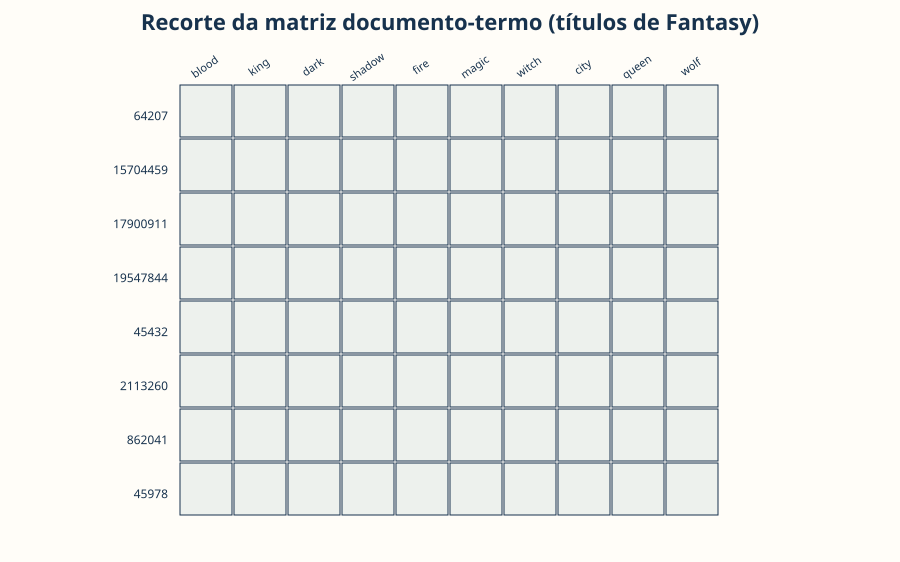

In [7]:
import math
import re
import unicodedata
from collections import Counter
from graficos import mapa_calor

STOPWORDS_EN = {"the", "a", "an", "of", "and", "in", "to", "for", "on", "at", "with", "from",
                "by", "my", "your", "is", "or", "her", "his", "our", "their", "its", "be",
                "as", "into", "about", "this", "that", "what", "how", "who", "when", "you",
                "me", "i", "it", "not", "no", "all", "one", "s", "de", "la", "el", "le",
                "vol", "volume", "book", "series"}

def tokenizar_titulo(texto):
    texto = re.sub(r"\(.*?\)", " ", str(texto))          # retira marcador de série
    base_txt = unicodedata.normalize("NFKD", texto.casefold())
    base_txt = "".join(c for c in base_txt if not unicodedata.combining(c))
    return [t for t in re.findall(r"[^\W\d_]+", base_txt) if t not in STOPWORDS_EN]

fantasy = e2[e2["genero_1"].eq("Fantasy")].copy()
fantasy["tokens"] = fantasy["titulo"].map(tokenizar_titulo)
fantasy = fantasy[fantasy["tokens"].map(len) > 0]
contagens = [Counter(t) for t in fantasy["tokens"]]
matriz_contagens = pd.DataFrame(contagens, index=fantasy["id_livro"]).fillna(0).astype(int)
print("Documentos (títulos de Fantasy):", matriz_contagens.shape[0], "| vocabulário:", matriz_contagens.shape[1])
print("Proporção de células iguais a zero:", round(float((matriz_contagens == 0).mean().mean()), 4))
display(fantasy.groupby(GRUPO).size().rename("títulos"))
mapa_calor(matriz_contagens.loc[:, matriz_contagens.sum().nlargest(10).index].head(8), "Recorte da matriz documento-termo (títulos de Fantasy)")

**Contagem, DF, IDF e TF-IDF** em dois títulos.

In [8]:
N = len(matriz_contagens)
df_termo = matriz_contagens.gt(0).sum(axis=0)
idf = ((N + 1) / (df_termo + 1)).map(math.log) + 1
matriz_tfidf = matriz_contagens.mul(idf, axis=1)

def pesos_documento(id_livro):
    linha = matriz_contagens.loc[id_livro]
    presentes = linha[linha > 0].index
    return pd.DataFrame({"contagem": linha[presentes], "df": df_termo[presentes],
                         "idf": idf[presentes], "tfidf": matriz_tfidf.loc[id_livro, presentes]}).sort_values("tfidf", ascending=False)

exemplos = fantasy[fantasy["titulo"].isin(["The Girl of Fire and Thorns", "The Name of the Wind"])]
for _, livro in exemplos.iterrows():
    print(f"\n{livro['titulo']} ({livro['autor']}, {livro[GRUPO]})")
    display(pesos_documento(livro["id_livro"]).round(3))


The Name of the Wind (Patrick Rothfuss, masculino)


,contagem,df,idf,tfidf
name,1,1,7.362,7.362
wind,1,4,6.446,6.446



The Girl of Fire and Thorns (Rae Carson, feminino)


,contagem,df,idf,tfidf
thorns,1,4,6.446,6.446
girl,1,11,5.570,5.570
fire,1,17,5.165,5.165


**Termos distintivos entre subconjuntos** (média de TF-IDF de títulos de autoras menos a de autores; últimas colunas: número de títulos com o termo).

In [9]:
grupo_titulo = fantasy.set_index("id_livro")[GRUPO]
media_tfidf = matriz_tfidf.groupby(grupo_titulo).mean()
contraste = media_tfidf.loc["feminino"] - media_tfidf.loc["masculino"]
presenca = matriz_contagens.gt(0).groupby(grupo_titulo).sum().T
tabela_contraste = pd.concat([
    contraste.nlargest(8).rename("contraste").to_frame().assign(sentido="maior em títulos de autoras"),
    contraste.nsmallest(8).rename("contraste").to_frame().assign(sentido="maior em títulos de autores"),
]).join(presenca)
tabela_contraste.round(4)

,contraste,sentido,feminino,masculino
fire,0.0934,maior em títulos de autoras,15,2
girl,0.0908,maior em títulos de autoras,11,0
dark,0.0705,maior em títulos de autoras,15,4
queen,0.0658,maior em títulos de autoras,11,2
wolf,0.0658,maior em títulos de autoras,11,2
angels,0.0634,maior em títulos de autoras,6,0
beauty,0.0557,maior em títulos de autoras,5,0
midnight,0.0543,maior em títulos de autoras,6,0
stone,-0.0663,maior em títulos de autores,2,7
magician,-0.0648,maior em títulos de autores,0,5


**Retorno aos títulos** que contêm dois termos examinados.

In [10]:
def titulos_com(termo, grupo=None, n=6):
    d = fantasy[fantasy["tokens"].map(lambda ts: termo in ts)]
    if grupo:
        d = d[d[GRUPO].eq(grupo)]
    return d[["id_livro", "titulo", "autor", GRUPO, "ano_publicacao"]].head(n)

display(titulos_com("blood"))
titulos_com("dragon")

,id_livro,titulo,autor,genero_E2_sem_duvidosos,ano_publicacao
761,43888,"The Sword of Truth, Boxed Set I: Wizard's Firs...",Terry Goodkind,masculino,1998
768,47953,The Black Jewels Trilogy: Daughter of the Bloo...,Anne Bishop,feminino,2003
922,6278019,Heart's Blood,Juliet Marillier,feminino,2009
1671,18943358,Saffron - The Blood Swan,D. Aswini,masculino,2013
2541,16114201,Descent of Blood,Elizabeth Marx,feminino,2012
2600,15793154,Blood's Pride,Evie Manieri,feminino,2012


,id_livro,titulo,autor,genero_E2_sem_duvidosos,ano_publicacao
4602,25850401,Jellybean the Dragon,Elias Zapple,masculino,2013
4628,35711572,Bentwhistle the Dragon in a Threat from the Past,Paul Cude,masculino,2011
4875,435415,Tea with the Black Dragon,R.A. MacAvoy,feminino,1983
6628,61942,The Dragonriders of Pern: Dragonflight / Drago...,Anne McCaffrey,feminino,1968
7984,17660564,Dragon Mine,Jaime Rush,masculino,2013
8246,25721483,In the Shadow of the Dragon King,J. Keller Ford,feminino,2016


O contraste depende do conteúdo repetitivo criado para os dados fictícios e da
distribuição dos temas pelos anos. Para interpretar um termo, retorne aos textos
e concordâncias; o peso não explica por que ele aparece.

> **Nota sobre atividades em dupla, trio ou revisão por pares.** Esta resolução
> foi produzida por uma única pessoa. Onde o roteiro pede colegas, apresento uma
> **revisão crítica simulada**, guiada pelas perguntas do roteiro. Ela não
> substitui o trabalho e o parecer de colegas reais.

## U05-A04 — Atividade integrada — matriz documentada

**Modalidade:** dupla. **Tempo:** 35 minutos.

1. documente tokenização e vocabulário;
2. construa uma matriz documento-termo;
3. compare contagem e TF-IDF em dois documentos;
4. identifique dois termos distintivos entre subconjuntos;
5. leia os trechos e registre uma interpretação e uma perda do modelo.

**Minha regra e matriz:** documentos = títulos dos livros de **Fantasy** (gênero
principal), escolhido por ser o gênero grande mais equilibrado entre os grupos
(675 títulos de autoras e 483 de autores na E2). Comparar dentro de um gênero
evita que a matriz apenas reproduza a diferença entre gêneros literários
(Unidade 4). Regra: retirar o marcador de série entre parênteses; minúsculas
com `casefold`; remoção de acentos; tokens = sequências de letras; retirada de
45 palavras funcionais e de quatro palavras editoriais (“vol”, “volume”, “book”,
“series”). Resultado: 1.158 documentos e 1.524 termos. A matriz é quase toda
vazia (99,86% das células são zero), porque cada título tem poucas palavras.
TF = contagem bruta; IDF suavizado, como no notebook:
idf = ln((N + 1)/(df + 1)) + 1.

**Contagem × TF-IDF em dois documentos:** em *The Name of the Wind* (Patrick
Rothfuss), “name” e “wind” têm contagem 1, mas “name” recebe peso maior (7,36
contra 6,45) porque aparece em um único título, e “wind” em quatro. Em *The Girl
of Fire and Thorns* (Rae Carson), as três palavras têm contagem 1; o TF-IDF
ordena “thorns” (df = 4; 6,45), “girl” (df = 11; 5,57) e “fire” (df = 17; 5,17).
Em títulos curtos, a contagem quase nunca passa de 1, então o TF-IDF depende
quase só da raridade do termo.

**Termos e trechos examinados:** pela média de TF-IDF por grupo, “fire”
(15 títulos de autoras, 2 de autores) e “girl” (11 e 0) são os mais
característicos de títulos de autoras; “stone” (2 e 7) e “magician” (0 e 5), de
títulos de autores. Leitura dos títulos: “blood” aparece em títulos de autoras
como *Heart's Blood* e *Blood's Pride*, mas também em um *boxed set* de Terry
Goodkind; “dragon” aparece em títulos dos dois grupos (Anne McCaffrey, R. A.
MacAvoy, Paul Cude). *Interpretação:* dentro de Fantasy, os títulos de autoras
recorrem mais a personagens femininas e elementos sensoriais (“girl”, “queen”,
“beauty”, “midnight”) e os de autores, a objetos e funções da fantasia épica
(“sword”, “stone”, “magician”, “chronicles”). As contagens são pequenas (de 0 a
15 títulos por termo): o contraste é uma pista para leitura, não uma regra.

**Perdas da representação:** a ordem das palavras (*The Girl King* e *King of
Thorns* têm sentidos muito diferentes); o subtítulo e a série, retirados com os
parênteses; a relação entre título e conteúdo do livro; e qualquer palavra da
lista de palavras funcionais, inclusive “her” e “his”, que poderiam marcar
gênero.

Leve a matriz e suas regras ao Notebook 04. A partir delas calcularemos Jaccard
e cosseno e as compararemos à distância de edição entre versões.